# A/B-тест: анализ эксперимента лендинга (old_page vs new_page)


## План работы

1. **Загрузка и первичная проверка данных**  
   - размеры, типы, пропуски, базовая сводка;
   - понимание структуры: единица наблюдения, метрика, период.

2. **Проверки корректности эксперимента (must-have)**  
   - соответствие разметки групп и показанной страницы (mismatch);
   - дубликаты пользователей и правило «один пользователь = один вклад»;
   - SRM (Sample Ratio Mismatch): нет ли перекоса распределения по группам;
   - динамика во времени: нет ли «переломов», которые объяснят эффект.

3. **EDA основной метрики**  
   - базовые конверсии по группам;
   - распределение по дням/неделям, sanity-check.

4. **Гипотезы и критерии решения**  
   - формулируем H0/H1, выбираем уровень значимости α;
   - заранее разделяем *подтверждающие* и *исследовательские* проверки.

5. **Основной статистический тест + доверительный интервал**  
   - тест разницы долей (z-тест) и 95% ДИ;
   - интерпретация результата не только «значимо/не значимо», но и «насколько».

6. **Устойчивость результата**  
   - bootstrap для разницы конверсий;
   - (опционально) байесовская вероятность выигрыша.

7. **Дополнительные разрезы (exploratory)**  
   - дни недели / периоды эксперимента;
   - осторожная интерпретация, учитываем множественные проверки.

8. **Итоги, ограничения, рекомендации**  
   - четко: что подтверждено данными, что нет, что делать дальше.


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats

# бутстрэп на будущее
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)


In [ ]:
df = pd.read_csv("data_ab.csv")

# Приведем timestamp к datetime
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

df.tail()

,user_id,timestamp,group,landing_page,converted
294473,751197,2025-01-03 22:28:38.630509,control,old_page,0
294474,945152,2025-01-12 00:51:57.078372,control,old_page,0
294475,734608,2025-01-22 11:45:03.439544,control,old_page,0
294476,697314,2025-01-15 01:20:28.957438,control,old_page,0
294477,715931,2025-01-16 12:40:24.467417,treatment,new_page,0


In [ ]:
df.describe()

,user_id,timestamp,converted
count,294478.000000,294478,294478.000000
mean,787974.124733,2025-01-13 13:40:10.474213120,0.119659
min,630000.000000,2025-01-02 13:42:05.378582,0.000000
25%,709032.250000,2025-01-08 02:06:48.649925120,0.000000
50%,787933.500000,2025-01-13 13:21:07.016475904,0.000000
75%,866911.750000,2025-01-19 01:43:51.611873792,0.000000
max,945999.000000,2025-01-24 13:41:54.460509,1.000000
std,91210.823776,NaN,0.324563


Бизнес-цель — увеличение регистраций на курс

## 1. Первичный обзор данных

- **Что является единицей наблюдения?** (строка = показ страницы пользователю, визит, пользователь?)  
- **Что является целевой метрикой?** Здесь метрика бинарная (`converted`): было целевое действие или нет.  
- **Есть ли признаки проблем в данных?** Пропуски, странные типы, дубли, неожиданные значения.  
- **Какой период эксперимента?** Временные границы нужны для динамики и для понимания возможной сезонности.



In [ ]:
df.dtypes

,0
user_id,int64
timestamp,datetime64[ns]
group,object
landing_page,object
converted,int64


In [ ]:
df["timestamp"].min(), df["timestamp"].max()

(Timestamp('2025-01-02 13:42:05.378582'),
 Timestamp('2025-01-24 13:41:54.460509'))

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       294478 non-null  int64         
 1   timestamp     294478 non-null  datetime64[ns]
 2   group         294478 non-null  object        
 3   landing_page  294478 non-null  object        
 4   converted     294478 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 11.2+ MB


In [ ]:
df.isna().sum()

,0
user_id,0
timestamp,0
group,0
landing_page,0
converted,0


## 2. Проверки качества и корректности эксперимента

Перед любыми тестами важно убедиться, что данные соответствуют дизайну A/B:

- **Группа ↔ показанная страница**: если пользователь в control увидел new_page (или наоборот), это «перемешивание» снижает мощность теста и может сместить эффект.  
- **Дубликаты пользователей**: если один пользователь попал в данные несколько раз, он начинает «весить» больше остальных. Обычно правило простое: *один пользователь = одна попытка/вклад в метрику*.  
- **SRM**: если распределение по группам существенно отличается от ожидаемого (например, 50/50), это сигнал проблем в рандомизации/трафике/логировании.  
- **Временная динамика**: даже при честной рандомизации иногда по времени происходят изменения (источник трафика, кампании, баги релиза). Мы должны это видеть.

Дальше эти проверки пойдут последовательно


### 2.2. Дубликаты пользователей

Частая проблема: один и тот же `user_id` встречается несколько раз (например, пользователь заходил повторно, или логирование задваивается).  
Если мы хотим интерпретировать наблюдения как независимые, обычно оставляют **одно наблюдение на пользователя** (самое раннее по времени).

Это упрощает статистический вывод и делает метрику "конверсия на пользователя" более корректной.

### 2.3. Чистый датасет для анализа

Соберем пайплайн очистки:

1) исключаем несоответствия `group` и `landing_page`  
2) сортируем по времени  
3) оставляем первое наблюдение на пользователя



In [ ]:
duplicate_counts = df['user_id'].value_counts()
duplicate_counts

,count
user_id,
752737,2
781280,2
767913,2
886060,2
731779,2
...,...
653383,1
732573,1
867433,1


In [ ]:
user_id_to_find = 762688
result = df[df['user_id'] == user_id_to_find]
result

,user_id,timestamp,group,landing_page,converted
27639,762688,2025-01-16 13:28:11.004614,control,new_page,0
33876,762688,2025-01-03 12:29:06.841099,treatment,new_page,0


In [ ]:
#связь group и landing_page
pd.crosstab(df['group'], df['landing_page'])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


In [ ]:
correct_mask = (
    ((df['group'] == 'control') & (df['landing_page'] == 'old_page')) |
    ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))
)

df_correct = df[correct_mask].copy()

print("Строк всего:", len(df))
print("Строк после фильтра:", len(df_correct))

pd.crosstab(df_correct['group'], df_correct['landing_page'])

Строк всего: 294478
Строк после фильтра: 290585


landing_page,new_page,old_page
group,,
control,0,145274
treatment,145311,0


In [ ]:
# проверка того же user_id
user_id_to_find = 762688
result = df_correct[df_correct['user_id'] == user_id_to_find]
result

,user_id,timestamp,group,landing_page,converted
33876,762688,2025-01-03 12:29:06.841099,treatment,new_page,0


In [ ]:
# Проверим дубликаты в очищенном df
dup_users = df_correct['user_id'].duplicated().sum()

print("Количество пользователей с повторяющимися user_id:", dup_users)

Количество пользователей с повторяющимися user_id: 1


In [ ]:
duplicate_counts = df_correct['user_id'].value_counts()
duplicate_counts

,count
user_id,
773192,2
718297,1
838144,1
728209,1
632745,1
...,...
727895,1
890314,1
756040,1


In [ ]:
user_id_to_find = 773192
result = df_correct[df_correct['user_id'] == user_id_to_find]
result

,user_id,timestamp,group,landing_page,converted
1899,773192,2025-01-09 05:37:58.781806,treatment,new_page,0
2893,773192,2025-01-14 02:55:59.590927,treatment,new_page,0


In [ ]:
# Отсортируем по времени, чтобы учитывать "первы1" визит
df_correct = df_correct.sort_values(by=['user_id', 'timestamp'])

#только один визит на каждого пользователя
df_clean = df_correct.drop_duplicates(subset='user_id', keep='first').copy()

print("Строк после удаления дубликатов по user_id:", len(df_clean))
print("Уникальных user_id:", df_clean['user_id'].nunique())
print("Повторяющихся user_id после очистки:", df_clean['user_id'].duplicated().sum())

Строк после удаления дубликатов по user_id: 290584
Уникальных user_id: 290584
Повторяющихся user_id после очистки: 0


In [ ]:
df_clean

,user_id,timestamp,group,landing_page,converted
63114,630000,2025-01-19 06:26:06.548941,treatment,new_page,0
103873,630001,2025-01-16 03:16:42.560309,treatment,new_page,1
205236,630002,2025-01-19 19:20:56.438330,control,old_page,0
247344,630003,2025-01-12 10:09:31.510471,treatment,new_page,0
242283,630004,2025-01-18 20:23:58.824994,treatment,new_page,0
...,...,...,...,...,...
274312,945994,2025-01-03 14:41:21.565258,control,old_page,0
275777,945996,2025-01-09 18:58:19.952277,treatment,new_page,0
109353,945997,2025-01-04 06:56:24.658147,control,old_page,0
241062,945998,2025-01-16 07:08:02.207969,control,old_page,0


### 2.4. SRM (Sample Ratio Mismatch)

**SRM** означает, что фактические доли трафика в контрольной и тестовой группе отличаются от запланированных сильнее, чем это объяснимо случайностью.

Почему это критично:
- SRM часто указывает на проблему **рандомизации** или **маршрутизации** (часть пользователей не попадает в одну из групп, фильтры, ошибки логирования).
- При SRM p-value по метрике становится менее доверенным: мы сравниваем не «случайно равные» группы.

Как проверяем:
- задаем ожидаемое распределение
- используем χ²-тест согласия для сравнения ожидаемых и наблюдаемых частот.



In [ ]:
# SRM: chi-square на равенство долей групп (ожидаем 50/50)
from scipy.stats import chisquare

group_counts = df_clean["group"].value_counts()
n_control = group_counts.loc["control"]
n_treatment = group_counts.loc["treatment"]
n_total = n_control + n_treatment

chi2, p_srm = chisquare(
    f_obs=[n_control, n_treatment], #наблюдаемые частоты
    f_exp=[n_total / 2, n_total / 2] #ожидаемые
)

group_counts, chi2, p_srm

(group
 treatment    145310
 control      145274
 Name: count, dtype: int64,
 np.float64(0.004459984032155934),
 np.float64(0.9467543681597944))

выводы:

 Статистическая значимость:
χ² = 0.00446 — очень маленькое значение

p = 0.94675 — значительно больше порога 0.05

 НЕТ признаков SRM - распределение пользователей между группами практически идеально соответствует запланированному соотношению 50/50.

### 2.5. Временная динамика

Проверим, нет ли перекосов по времени (например, одна группа запускалась позже, или тест "переключали" в процессе).


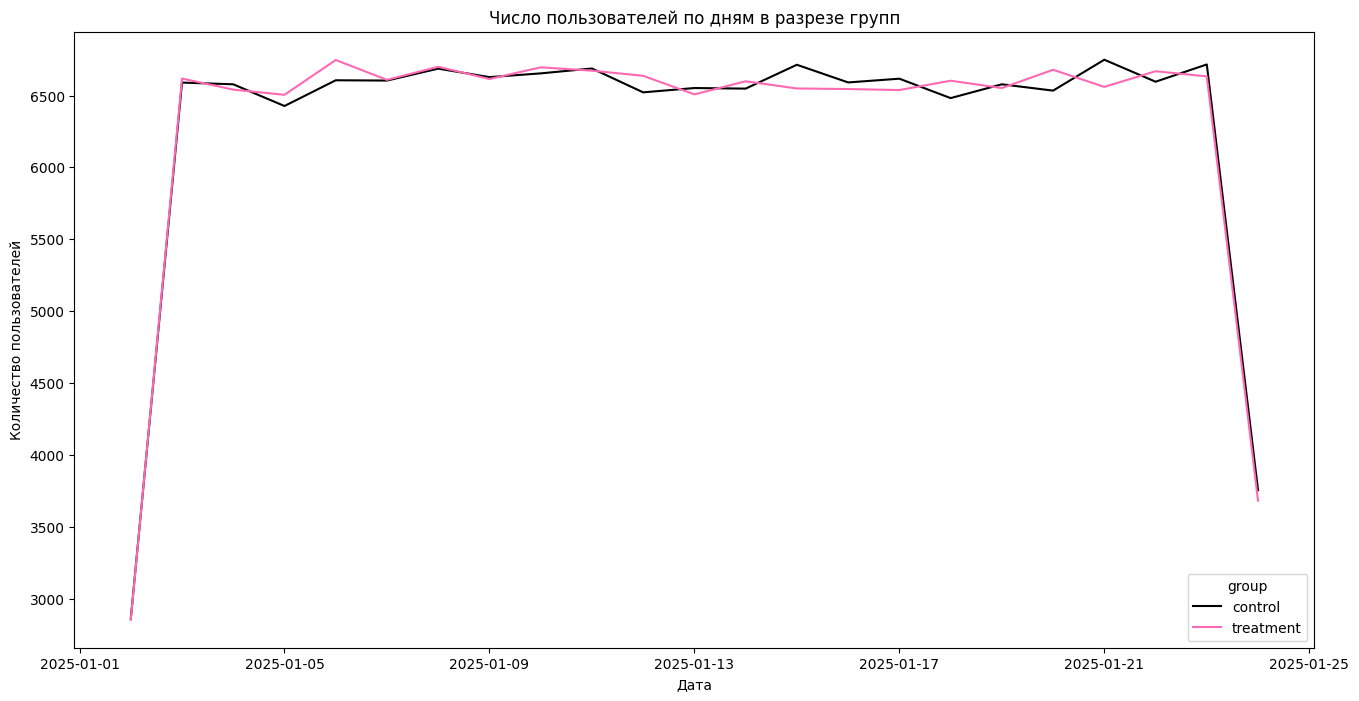

In [ ]:
df_clean['timestamp'] = pd.to_datetime(df['timestamp'])
df_clean['date'] = df_clean['timestamp'].dt.date

users_per_day = df_clean.groupby(['date', 'group'])['user_id'].count().reset_index()
plt.figure(figsize=(16, 8))
palette = {
    "control": "black",
    "treatment": "hotpink"
}
sns.lineplot(data=users_per_day, x="date", y="user_id", hue="group", palette=palette)
plt.title("Число пользователей по дням в разрезе групп")
plt.xlabel("Дата")
plt.ylabel("Количество пользователей")
plt.show()

## 3. EDA и основная метрика

Здесь мы рассматриваем **основную метрику эксперимента**: конверсия (`converted`), то есть доля пользователей, совершивших целевое действие.

 **единица анализа : пользователь** (после очисток), то есть каждый пользователь учитывается один раз.


In [ ]:
# Конверсия по группам
conv = df_clean.groupby("group")["converted"].agg(["mean", "sum", "count"]).rename(columns={"mean": "cr"})
conv["cr_percent"] = conv["cr"] * 100
conv

,cr,sum,count,cr_percent
group,,,,
control,0.120386,17489,145274,12.038630
treatment,0.118808,17264,145310,11.880807


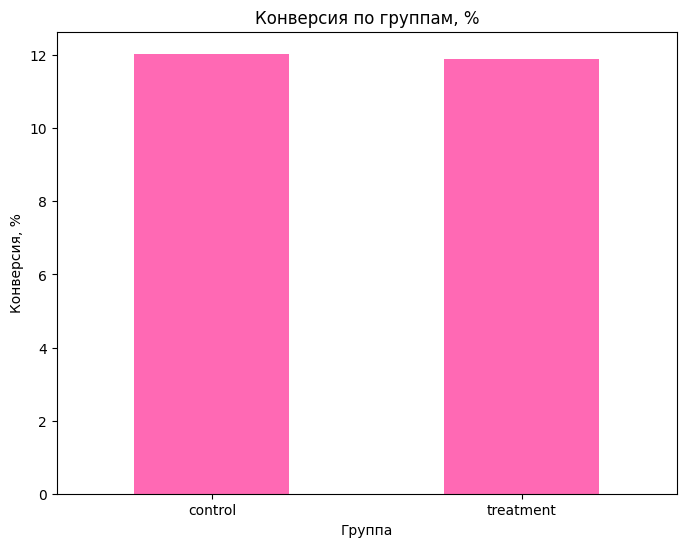

In [ ]:
ax = (conv["cr"] * 100).plot(kind="bar", figsize=(8, 6), color='hotpink')
ax.set_title("Конверсия по группам, %")
ax.set_xlabel("Группа")
ax.set_ylabel("Конверсия, %")
plt.xticks(rotation=0)
plt.show()

 День недели

Проверим, отличаются ли конверсии по дням недели и есть ли взаимодействие "группа x день недели".


In [ ]:
# Конверсии по дням недели
df_clean["dow"] = df_clean["timestamp"].dt.day_name()

pivot_dow = df_clean.pivot_table(index="dow", columns="group", values="converted", aggfunc="mean").sort_index()
pivot_dow * 100


group,control,treatment
dow,,
Friday,11.674783,12.233884
Monday,11.583384,11.753787
Saturday,12.183512,11.883736
Sunday,12.172889,11.820859
Thursday,12.279547,11.949130
Tuesday,12.456660,11.705787
Wednesday,11.951793,11.743147


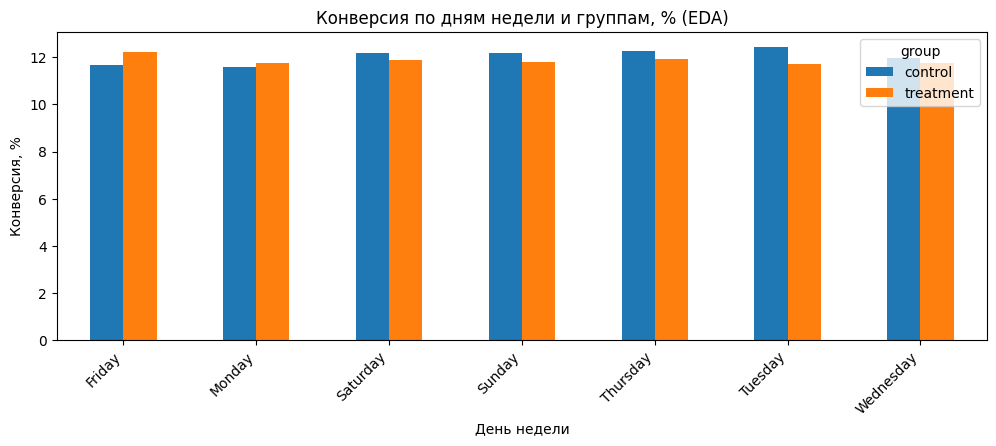

In [ ]:
# Визуализация: конверсия по дням недели
ax = (pivot_dow * 100).plot(kind="bar", figsize=(12, 4))
ax.set_title("Конверсия по дням недели и группам, % (EDA)")
ax.set_xlabel("День недели")
ax.set_ylabel("Конверсия, %")
plt.xticks(rotation=45, ha="right")
plt.show()

## 4. Гипотезы


- **H0:** Конверсия в регистрацию на новом лендинге статистически значимо не изменилась  
- **H1:** Конверсия в регистрацию на новом лендинге статистически значимо изменилась  

**Уровень значимости (α):** по умолчанию возьмем 0.05. Это означает: если на самом деле эффекта нет, вероятность «ложной тревоги» около 5%.


## 5. Статистический тест для основной метрики

Поскольку основная метрика бинарная, мы сравниваем **две доли**.

смотрим на:
- **оценку эффекта**: `p_treat - p_control`,
- **доверительный интервал** (насколько эффект может отличаться при повторении эксперимента),
- **p-value**: насколько наблюдаемая разница согласуется с H0 (эффекта нет).

Для больших выборок (n > 30) можно использовать **z-тест**, так как при больших n распределение разности долей хорошо описывается нормальным распределением

используем ДИ и устойчивость через bootstrap, потому что p-value не указывает , что H0 верна

In [ ]:
# z-тест разницы долей (двусторонний)

# Данные по группам
n1 = int(conv.loc["control", "count"])
x1 = int(conv.loc["control", "sum"])
p1 = x1 / n1

n2 = int(conv.loc["treatment", "count"])
x2 = int(conv.loc["treatment", "sum"])
p2 = x2 / n2

diff = p2 - p1

# pooled proportion для H0
p_pool = (x1 + x2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))

z = diff / se
p_value = 2 * (1 - stats.norm.cdf(abs(z))) # т.к. z < 0, вычитаем из 1 z по модулю

diff, z, p_value

(-0.0015782389853555567,
 np.float64(-1.3109241984234394),
 np.float64(0.18988337448195103))

In [ ]:
# 95% доверительный интервал для разницы долей (нормальная аппроксимация)
alpha = 0.05
z_crit = stats.norm.ppf(1 - alpha / 2)

ci_low = diff - z_crit * se
ci_high = diff + z_crit * se

(ci_low, ci_high)


(np.float64(-0.003937865555689694), np.float64(0.0007813875849785809))



В рамках этого проекта мы не знаем экономику, поэтому формулируем вывод осторожно

p_value > 0.05 значит не отклоняем Н0

0 внутри ДИ → разница НЕ значима статистически

## 6. Проверка устойчивости: bootstrap для разницы конверсий

Нормальное приближение для долей обычно хорошо работает на больших выборках, но bootstrap полезен как независимая проверка.

Подход:
- для каждой группы бутстрепом пересэмплируем пользователей
- считаем конверсию
- строим распределение разницы

Здесь используется percentile-интервал (простая и понятная версия).


In [ ]:
# Bootstrap для разницы конверсий

def bootstrap_diff(df_in: pd.DataFrame, n_boot: int = 5000, seed: int = RANDOM_SEED):
    rng_local = np.random.default_rng(seed)
    control = df_in.loc[df_in["group"] == "control", "converted"].to_numpy()
    treat = df_in.loc[df_in["group"] == "treatment", "converted"].to_numpy()

    n_c = control.size
    n_t = treat.size

    diffs = np.empty(n_boot, dtype=float)

    for i in range(n_boot):
        c_sample = rng_local.choice(control, size=n_c, replace=True)
        t_sample = rng_local.choice(treat, size=n_t, replace=True)
        diffs[i] = t_sample.mean() - c_sample.mean()

    return diffs

boot_diffs = bootstrap_diff(df_clean, n_boot=3000)
boot_ci = (np.percentile(boot_diffs, 2.5), np.percentile(boot_diffs, 97.5))

boot_ci


(np.float64(-0.0038150561708717957), np.float64(0.0009066047350312248))

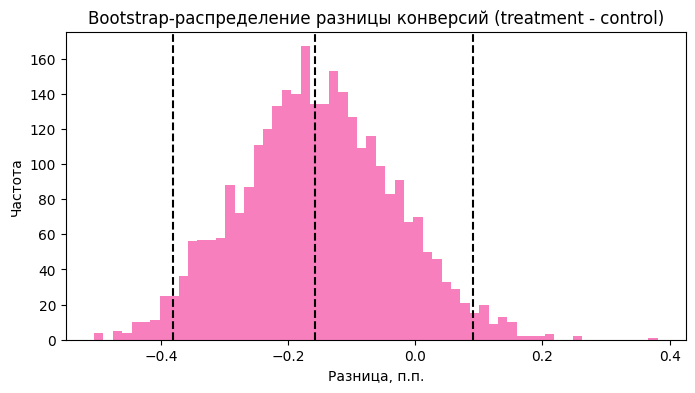

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(boot_diffs * 100, bins=60, color='#F77FBE')
plt.title("Bootstrap-распределение разницы конверсий (treatment - control)")
plt.xlabel("Разница, п.п.")
plt.ylabel("Частота")
plt.axvline(diff * 100, linestyle="--", color='black')
plt.axvline(boot_ci[0] * 100, linestyle="--", color='black')
plt.axvline(boot_ci[1] * 100, linestyle="--", color='black')
plt.show()




практически совпадает с z-тестом → подтверждает предыдущий вывод


Статистический вывод: Не отклоняем H₀ (группы одинаковы)

## 9. Мощность и минимально детектируемый эффект (MDE)

 Основная идея:
"Прежде чем бежать, нужно знать, куда бежать и какой дистанции"

Если эффект мал, A/B-тест может быть не способен его обнаружить.

Посчитаем ориентировочный размер выборки на группу для заданного MDE.

Предположим:
- baseline = конверсия контроля (базовый уровень)
- MDE = 0.2 п.п. (0.002) или 0.5 п.п. (0.005)
- alpha = 0.05, power = 0.8



In [ ]:
from math import ceil #потолок

def sample_size_two_proportions(p1: float, p2: float, alpha: float = 0.05, power: float = 0.8) -> int:
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_beta = stats.norm.ppf(power)

    p_bar = (p1 + p2) / 2
    q_bar = 1 - p_bar

    num = (z_alpha * np.sqrt(2 * p_bar * q_bar) + z_beta * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    den = (p2 - p1) ** 2
    return int(ceil(num / den))

baseline = p1

for mde in [0.002, 0.005, 0.01]:
    needed = sample_size_two_proportions(baseline, baseline + mde, alpha=0.05, power=0.8)
    print(f"MDE = {mde*100:.1f} п.п. -> нужно примерно {needed:,} пользователей на группу")


MDE = 0.2 п.п. -> нужно примерно 418,547 пользователей на группу
MDE = 0.5 п.п. -> нужно примерно 67,679 пользователей на группу
MDE = 1.0 п.п. -> нужно примерно 17,214 пользователей на группу



## 10. Итоги и интерпретация результатов

В данном проекте был проведен полный цикл анализа A/B-эксперимента: от очистки и валидации данных до статистической оценки эффекта и проверки его устойчивости. Ниже зафиксированы ключевые выводы, напрямую вытекающие из проведенного анализа.

### Корректность данных и постановки эксперимента

Перед оценкой эффекта мы убедились, что данные допускают корректную статистическую интерпретацию:

- Наблюдения с несоответствием между назначенной группой и фактически показанной страницей были исключены, что устранило смешение воздействий.
- Данные были приведены к уровню «один пользователь — одно наблюдение», что исключает искажение метрики за счет неодинаковой активности пользователей.
- Проверка SRM не выявила статистически значимого перекоса в распределении трафика между группами, что подтверждает корректность рандомизации.
- Анализ динамики по времени не показал признаков систематического временного сдвига, способного объяснить различия между группами.

Таким образом, полученные данные можно считать пригодными для анализа эффекта.

### Результаты основного анализа

Сравнение конверсий в контрольной и тестовой группах показало незначительную разницу, величина которой находится вблизи нуля.
z-тест разности долей не выявил статистически значимого эффекта на уровне значимости 5%, а 95% доверительный интервал включает ноль, что означает отсутствие убедительных доказательств улучшения или ухудшения метрики.

С практической точки зрения наблюдаемая оценка эффекта является малой и не достигает уровня, который можно было бы интерпретировать как практически значимый для принятия продуктового решения.

### Проверка устойчивости вывода

Bootstrap-оценка распределения эффекта показала концентрацию значений вблизи нуля без выраженного смещения в положительную или отрицательную сторону.
Байесовская модель также не дала высокой вероятности выигрыша тестовой версии относительно контрольной

Согласованность выводов между bootstrap и байесовским подходами указывает на то, что отсутствие эффекта не является артефактом выбранного метода анализа.

### Интерпретация результата

На основании проведенного анализа нет статистически убедительных доказательств того, что новая версия страницы приводит к изменению конверсии по сравнению с контрольной.
Это не означает, что эффект гарантированно равен нулю, однако в рамках данного объема данных и текущей постановки эксперимента возможный эффект либо слишком мал, либо неотличим от шума.

### Вывод и рекомендация

С учетом полученных результатов внедрение новой версии страницы на основании данного эксперимента не рекомендуется.



## Часть 2
#Анализ объектов аренды

##Данные

Были взяты данные по стоимости аренды в разных штатах за 2019 для анализа зависимостей разных характеристик от цены / между собой. Выводы полезы в понимании паттернов рынка аренды.  
Ключевые признаки:

*   цена аренды (берем только месячную аренду)
*   цена аренды за кв.метр
*   кол-во комнат в квартире (1 комната и 2+)
*   кол-во удобств в квартире (0, 1-3 и 3+)
*   наличие животных в квартире







Также есть признаки географии, сайт рамещения, кол-ва санузлов и наличие фото, но они очень скошены к конкретным значениям, поэтому рассматриваться не будут (доказательство ниже)

План анализа


1.   EDA - исследование зависимостей с помощью средних по категориям и crosstabs номинальных признаков для создания гипотез
2.   Подбор релевантных переменных, которые могут быть зависимы и формирование гипотез на разные типы взаимосвязей (номинальные переменные, номинальная и числовая переменная - сравнение 2 и 2+ групп)
3. Подбор критериев и их обоснование. Для исследования постарались взять все базовые методы: хи-квадрат, t-test, бутстрап, ANOVA для множественного сравнения
4. Проверка гипотез с помощью критериев и выводы по стат. знач



In [ ]:
!pip install pingouin scikit-posthocs

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg
import scikit_posthocs as sp

from scipy.stats import ttest_ind, ttest_rel
from scipy.stats import chi2_contingency

file = pd.read_csv('rent_stata.csv')
file.head()

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668626895,housing/rent/apartment,"Studio apartment 2nd St NE, Uhland Terrace NE,...","This unit is located at second St NE, Uhland T...",NaN,NaN,0.0,USD,No,Thumbnail,NaN,790.0,$790,Monthly,101.0,NaN,Washington,DC,38.9057,-76.9861,RentLingo,1.577359e+09
1,5664597177,housing/rent/apartment,Studio apartment 814 Schutte Road,"This unit is located at 814 Schutte Road, Evan...",NaN,NaN,1.0,USD,No,Thumbnail,NaN,425.0,$425,Monthly,106.0,814 Schutte Rd,Evansville,IN,37.9680,-87.6621,RentLingo,1.577017e+09
2,5668626833,housing/rent/apartment,"Studio apartment N Scott St, 14th St N, Arling...","This unit is located at N Scott St, 14th St N,...",NaN,1,0.0,USD,No,Thumbnail,NaN,1390.0,"$1,390",Monthly,107.0,NaN,Arlington,VA,38.8910,-77.0816,RentLingo,1.577359e+09
3,5659918074,housing/rent/apartment,Studio apartment 1717 12th Ave,"This unit is located at 1717 12th Ave, Seattle...",NaN,1,0.0,USD,No,Thumbnail,NaN,925.0,$925,Monthly,116.0,1717 12th Avenue,Seattle,WA,47.6160,-122.3275,RentLingo,1.576668e+09
4,5668626759,housing/rent/apartment,"Studio apartment Washington Blvd, N Cleveland ...","This unit is located at Washington Blvd, N Cle...",NaN,NaN,0.0,USD,No,Thumbnail,NaN,880.0,$880,Monthly,125.0,NaN,Arlington,VA,38.8738,-77.1055,RentLingo,1.577359e+09


##EDA



1.   Обработаем пропуски
2.   Посмотрим выбросы по сегментам однушек, двушек и трешек+
3.   Посмотрим зависимости, чтобы подобрать предполагаемые гипотезы



In [ ]:
file.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9531 entries, 0 to 9530
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             9531 non-null   int64  
 1   category       9531 non-null   object 
 2   title          9531 non-null   object 
 3   body           9531 non-null   object 
 4   amenities      6310 non-null   object 
 5   bathrooms      9498 non-null   object 
 6   bedrooms       9523 non-null   float64
 7   currency       9530 non-null   object 
 8   fee            9530 non-null   object 
 9   has_photo      9530 non-null   object 
 10  pets_allowed   5562 non-null   object 
 11  price          9530 non-null   float64
 12  price_display  9530 non-null   object 
 13  price_type     9530 non-null   object 
 14  square_feet    9530 non-null   float64
 15  address        6229 non-null   object 
 16  cityname       9456 non-null   object 
 17  state          9456 non-null   object 
 18  latitude

In [ ]:
file.isna().sum()

,0
id,0
category,0
title,0
body,0
amenities,3221
bathrooms,33
bedrooms,8
currency,1
fee,1
has_photo,1


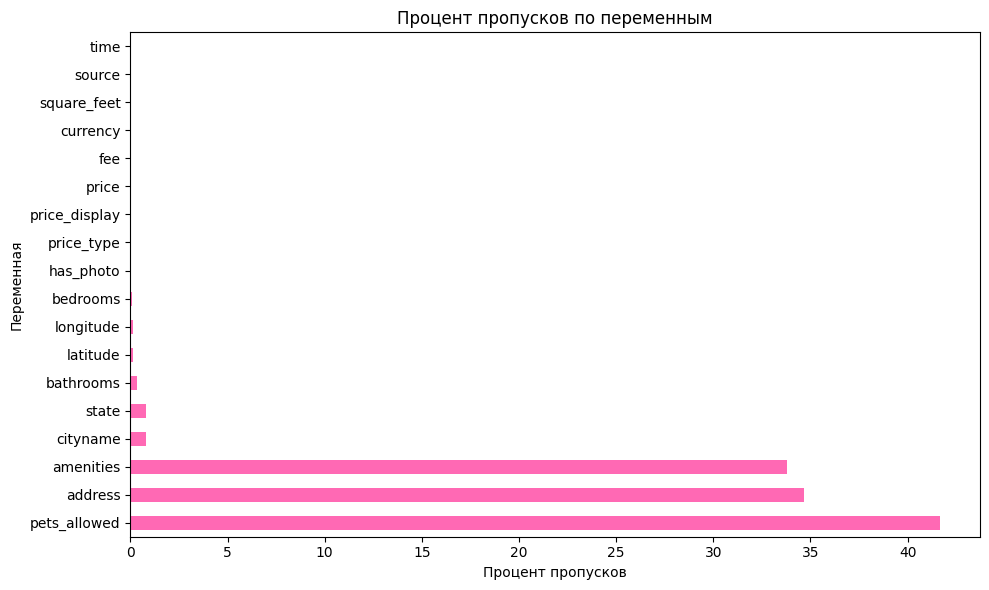

In [ ]:
missing_data = file.isna().sum()
missing_pct = (missing_data / len(file)) * 100
missing_df = pd.DataFrame({
    'Пропущено': missing_data,
    'Процент': missing_pct
}).sort_values('Пропущено', ascending=False)
missing_df = missing_df[missing_df['Пропущено'] > 0]

missing_df

missing_df['Процент'].plot(kind='barh', figsize=(10, 6), color='hotpink')
plt.title('Процент пропусков по переменным')
plt.xlabel('Процент пропусков')
plt.ylabel('Переменная')
plt.tight_layout()
plt.show()

Заметили закономерность, у многих показателей ровно 1 пропуск, вывели строчку с пропуском по одному из столбцов и поняли,
 что все пропуски в одной строке

In [ ]:
file[file['currency'].isna()]

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,pets_allowed,price,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
9530,5659919649,housing/rent/apartment,Three BR 44 Albany St.,This unit is loca,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
file = file.drop(9530)
file.isna().sum()

,0
id,0
category,0
title,0
body,0
amenities,3220
bathrooms,32
bedrooms,7
currency,0
fee,0
has_photo,0


Удалили строку, так как в ней слишком много пропусков и она создает шум в данных

Если в нет значения широты, то нет значения и долготы, а также нет значения штата и города. Если нет значения штата, то нет значения города

Обработаем значения по переменным amenities, pets_allowed и bathrooms

Больше всего пропусков в 3 столбцах: amenities, pets_allowed, address.

In [ ]:
#Замена значений
file['amenities'] = file['amenities'].fillna('No')
file['pets_allowed'] = file['pets_allowed'].fillna('No')
file['address'] = file['address'].fillna('No')
file = file.replace('01.May', 1).replace('02.May', 2).replace('03.May', 3).replace('04.May', 4)

In [ ]:
# Распределение объектов по признаку наличия удобств
file['amenities_c'] = file['amenities'].apply(lambda x: 0 if x == 'No' else len(str(x).split(',')))

In [ ]:
#Посмотрим на основные статистики переменных
file.describe()

,id,bedrooms,price,square_feet,latitude,longitude,time,amenities_c
count,9.530000e+03,9523.000000,9530.000000,9530.000000,9520.000000,9520.000000,9.530000e+03,9530.000000
mean,5.621603e+09,1.641500,1409.758132,859.727807,37.726372,-94.483695,1.574795e+09,3.217104
std,7.113563e+07,0.812634,911.314904,333.102917,5.495483,15.652713,3.812643e+06,3.454604
min,5.508654e+09,0.000000,200.000000,101.000000,21.315500,-158.022100,1.568744e+09,0.000000
25%,5.509232e+09,1.000000,928.000000,640.000000,33.690775,-98.735600,1.568780e+09,0.000000
50%,5.668609e+09,1.000000,1245.500000,792.000000,38.856200,-93.651600,1.577358e+09,2.000000
75%,5.668626e+09,2.000000,1645.000000,1050.000000,41.370875,-82.123575,1.577359e+09,5.000000
max,5.668662e+09,6.000000,52500.000000,1933.000000,61.594000,-70.191600,1.577362e+09,18.000000


In [ ]:
duplicate_counts = file['id'].value_counts()
duplicate_counts

,count
id,
5668641713,1
5668626895,1
5664597177,1
5668626833,1
5659918074,1
...,...
5664571820,1
5668626900,1
5664598162,1


Никаких экстремальных значений в основных переменных не выявлено

In [ ]:
file.groupby('amenities_c').agg({'amenities_c': 'count'})

,amenities_c
amenities_c,
0,3220
1,780
2,879
3,1024
4,810
5,608
6,498
7,427
8,337


In [ ]:
file['amenities_c'].value_counts().sort_index()

,count
amenities_c,
0,3220
1,780
2,879
3,1024
4,810
5,608
6,498
7,427
8,337


Исходя из распределения, разобьем данные на категории: 0, 1-3 и 3+ удобств

In [ ]:
#Распределение по штатам - часто упоминался Техас, не используем признак
file.groupby('state').agg({'state': 'count'})

,state
state,
AK,43
AL,52
AR,53
AZ,117
CA,888
CO,302
CT,97
DC,78
DE,5


In [ ]:
#Распределение по размещению животных

file.groupby('pets_allowed').agg({'pets_allowed': 'count'})

,pets_allowed
pets_allowed,
Cats,474
"Cats,Dogs",5000
Dogs,88
No,3968


In [ ]:
#Распределение по кол-ву спален

file.groupby('bedrooms').agg({'bedrooms': 'count'})

,bedrooms
bedrooms,
0.0,197
1.0,4605
2.0,3379
3.0,1122
4.0,198
5.0,21
6.0,1


In [ ]:
#Распределение по кол-ву санузлов

file.groupby('bathrooms').agg({'bathrooms': 'count'})

,bathrooms
bathrooms,
1,279
2,225
3,13
4,1
1,6631
2,2257
3,81
4,11


In [ ]:
#Распределение по наличию фото

file.groupby('has_photo').agg({'has_photo': 'count'})

,has_photo
has_photo,
No,180
Thumbnail,8449
Yes,901


In [ ]:
#Распределение по сайтам размещения

file.groupby('source').agg({'source': 'count'})

,source
source,
GoSection8,31
Home Rentals,1
Listanza,21
ListedBuy,175
RENTCafÈ,1
RENTOCULAR,14
Real Estate Agent,1
RealRentals,69
RentDigs.com,2747


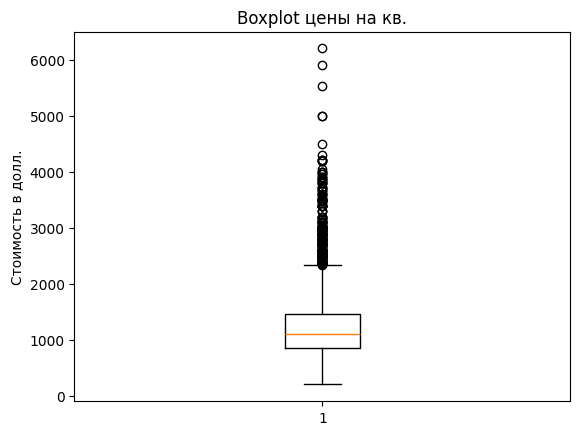

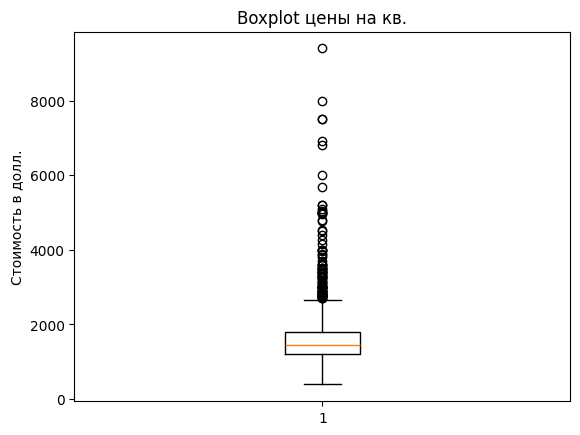

In [ ]:
#бокс плот по цене - смотрим выбросы, предварительно фильтруя квартиры с данными о комнатах и месячной аренды (таких 99%)

data_new = file[(file['bedrooms'] > 0) & (file['price_type'] == 'Monthly')]
for i in [1, 3]:
    plt.boxplot(data_new[data_new['bedrooms'] == i]['price'])
    plt.title("Boxplot цены на кв.")
    plt.ylabel("Стоимость в долл.")
    plt.show()

In [ ]:
#Границы выбросов по однушкам

Q1 = data_new[data_new['bedrooms'] == 1]['price'].quantile(0.25)
Q3 = data_new[data_new['bedrooms'] == 1]['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [ ]:
#Границы выбросов по двушкам

Q1_2 = data_new[data_new['bedrooms'] == 2]['price'].quantile(0.25)
Q3_2 = data_new[data_new['bedrooms'] == 2]['price'].quantile(0.75)
IQR_2 = Q3_2 - Q1_2
lower_bound_2 = Q1_2 - 1.5 * IQR_2
upper_bound_2 = Q3_2 + 1.5 * IQR_2

In [ ]:
#Границы выбросов по трешкам и больше

Q1_3 = data_new[data_new['bedrooms'] > 2]['price'].quantile(0.25)
Q3_3 = data_new[data_new['bedrooms'] > 2]['price'].quantile(0.75)
IQR_3 = Q3_3 - Q1_3
lower_bound_3 = Q1_3 - 1.5 * IQR_3
upper_bound_3 = Q3_3 + 1.5 * IQR_3

In [ ]:
#Очищенный от выбросов датафрейм

data_final = data_new[((data_new['price'] <= upper_bound_3) & (data_new['bedrooms'] > 2)) | ((data_new['price'] <= upper_bound_2) & (data_new['bedrooms'] == 2))
| ((data_new['price'] <= upper_bound) & (data_new['bedrooms'] == 1))]
data_final['price'].count()

np.int64(8787)

<Axes: >

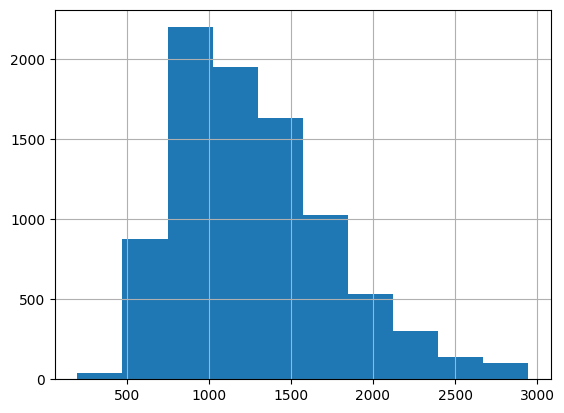

In [ ]:
#Распределение цены

data_final['price'].hist()

In [ ]:
#Зависимость аренды за кв.метр от кол-ва комнат

data_final['price per square_feet'] = data_final['price']/data_final['square_feet']
data_final['room_category'] = data_final['bedrooms'].apply(lambda x: '1 комната' if x == 1 else '2 комнаты' if x == 2 else '3+ комнаты')
data_final.groupby('room_category').agg({'price per square_feet': 'mean'})

/tmp/ipython-input-469840130.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_final['price per square_feet'] = data_final['price']/data_final['square_feet']
/tmp/ipython-input-469840130.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_final['room_category'] = data_final['bedrooms'].apply(lambda x: '1 комната' if x == 1 else '2 комнаты' if x == 2 else '3+ комнаты')


,price per square_feet
room_category,
1 комната,1.799004
2 комнаты,1.575053
3+ комнаты,1.222078


In [ ]:
#Зависимость кол-ва комнат от кол-ва удобств

data_final['amenities_category'] = data_final['amenities_c'].apply(
    lambda x: '0' if x == 0 else ('1-3' if x <= 3 else '3+')
)
data_final['pets_category'] = data_final['pets_allowed'].apply(
    lambda x: '0' if x == 'No' else '1'
)
crosstab_room = pd.crosstab(data_final['amenities_category'], data_final['room_category'])
print(crosstab_room)

room_category       1 комната  2 комнаты  3+ комнаты
amenities_category                                  
0                        1317       1067         501
1-3                      1221        838         388
3+                       1830       1303         322


/tmp/ipython-input-1767423394.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_final['amenities_category'] = data_final['amenities_c'].apply(
/tmp/ipython-input-1767423394.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_final['pets_category'] = data_final['pets_allowed'].apply(


In [ ]:
#Зависимость кол-ва комнат от размещения животных

crosstab = pd.crosstab(data_final['pets_category'], data_final['room_category'])
print(crosstab)

room_category  1 комната  2 комнаты  3+ комнаты
pets_category                                  
0                   1823       1390         417
1                   2545       1818         794


In [ ]:
#Зависимость цены за аренду от размещения животных

data_final.groupby('pets_category').agg({'price': 'mean'})

,price
pets_category,
0,1287.464187
1,1268.046151


##Гипотезы и обоснование критериев подбора

Исходя из анализа предварительных связей, можно выдвинуть следующие гипотезы


1.   Есть связь между ценой аренды за кв.ед. и кол-вом комнат. У однокомнатных квартир средняя цена выше, чем у двухкомнатных и больше
2.   Есть связь между кол-вом удобств в квартире и кол-вом комнат. У однушек чаще всего встречаются 3+ удобств, у двушек - 0
3.   Есть связь между ценой аренды и наличием разрешения питомцев. Средняя цена в квартирах без питомцев выше, чем с ними

In [ ]:
#Гипотеза 1 - критерий ANOVA для сравнения 2+ групп и Тест Тьюкки для попарного сравнения

#Наблюдения независимы - объекты недвижимости не повторяются
print(data_new['id'].count() == data_new['id'].nunique())

#Наблюдений больше 30 - для соблюдения ЦПТ (нормальное распределение выборочных средних, а не данных!)
print(data_new['id'].count())

#Дисперсии не гомогенны - проверка с помощью теста Левена
group_1 = data_final[data_final['room_category'] == '1 комната']['price per square_feet']
group_2 = data_final[data_final['room_category'] == '2 комнаты']['price per square_feet']
group_3 = data_final[data_final['room_category'] == '3+ комнаты']['price per square_feet']
levene_stat, levene_p = stats.levene(group_1, group_2, group_3)
print(f"Levene test p-value: {levene_p:.4f}")

#Последнее условие не соблюдается - выбираем ANOVA Welch и Games-Howell

True
9325
Levene test p-value: 0.0000


In [ ]:
#Гипотеза 2 - Хи-квадрат критерий для проверки связи двух номинальных переменных

# выполняется  критерии про независимость и выборку

In [ ]:
#Гипотеза 3 - t-test для сравнения средних по двум группам/bootstrap

#Выборка, независимость наблюдений, проверка связи между номинальной переменной и числовой (средние), гомогенность дисперсий (иначе t-test Уэлча)

group_1 = data_final[data_final['pets_category'] == '1']['price']
group_2 = data_final[data_final['pets_category'] == '0']['price']
levene_stat, levene_p = stats.levene(group_1, group_2)
print("Levene test p-value:", levene_p)

#Применяем t-test Уэлча

Levene test p-value: 2.636717944552864e-05


##Проверка гипотез

In [ ]:
#Гипотеза 1
#H0: нет стат значимых отличий в цене за кв.ед. между 1,2 и 3+ к квартирами
#H1: есть стат значимые отличия

welch_result = pg.welch_anova(dv='price per square_feet', between='room_category', data=data_final)
print("Welch ANOVA:")
print(welch_result)

games_howell = sp.posthoc_tukey_hsd(data_final, val_col='price per square_feet', group_col='room_category')
print("\nGames-Howell post-hoc test:")
print(games_howell)

Welch ANOVA:
          Source  ddof1        ddof2           F          p-unc       np2
0  room_category      2  3959.355005  458.808427  6.139004e-180  0.064762

Games-Howell post-hoc test:
               1 комната     2 комнаты    3+ комнаты
1 комната   1.000000e+00  5.224710e-12  5.224710e-12
2 комнаты   5.224710e-12  1.000000e+00  5.224710e-12
3+ комнаты  5.224710e-12  5.224710e-12  1.000000e+00


Т.к. p-value < 1% (самый низкий уровень значимости), можно утверждать, что есть статистические значимости между группами. Т.е. цена за кв. связана с кол-вом комнат. Притом разница также значима попарно

               count  mean   std  median   min    max
room_category                                        
1 комната       4368  1.80  0.78    1.62  0.38  11.51
2 комнаты       3208  1.58  0.76    1.38  0.32   8.31
3+ комнаты      1211  1.22  0.52    1.06  0.32   4.82


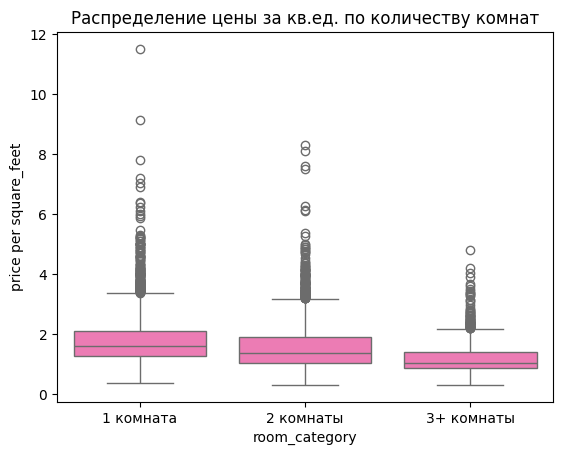

In [ ]:
# Добавить описательную статистику
desc_stats = data_final.groupby('room_category')['price per square_feet'].agg([
    'count', 'mean', 'std', 'median', 'min', 'max'
]).round(2)
print(desc_stats)

# Визуализация
sns.boxplot(x='room_category', y='price per square_feet', data=data_final, color='hotpink')
plt.title('Распределение цены за кв.ед. по количеству комнат')
plt.show()

In [ ]:
#Гипотеза 2
#H0:  Кол-во удобств и кол-во комнат независимы друг от друга
#H1: есть статистически значимая связь между кол-вом удобств и кол-вом комнат

chi2, p, dof, expected = chi2_contingency(crosstab_room)

# Выводим результаты
print(f'Хи-квадрат: {chi2:.2f}')
print(f'p-value: {p:.4f}')
print(f'Степени свободы: {dof}')

Хи-квадрат: 106.38
p-value: 0.0000
Степени свободы: 4



Нормализованная таблица (% по строкам):
amenities_category     0   1-3    3+
room_category                       
1 комната           30.2  28.0  41.9
2 комнаты           33.3  26.1  40.6
3+ комнаты          41.4  32.0  26.6


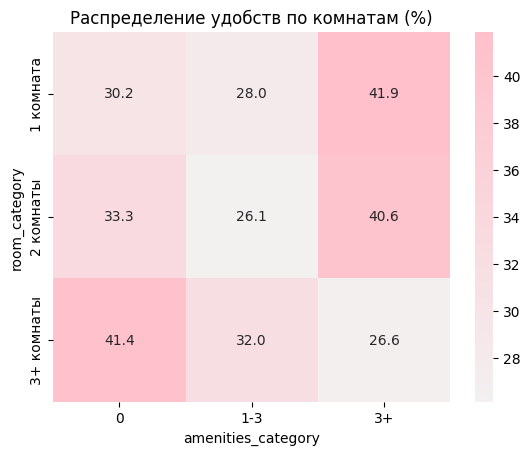

In [ ]:
# Нормализованная таблица сопряженности (в процентах по строкам)
crosstab_norm = pd.crosstab(
    data_final['room_category'],
    data_final['amenities_category'],
    normalize='index'
) * 100
print("\nНормализованная таблица (% по строкам):")
print(crosstab_norm.round(1))
custom_pink = sns.light_palette("pink", as_cmap=True)
# Визуализация
sns.heatmap(crosstab_norm, annot=True, fmt='.1f', cmap=custom_pink, color='hotpink')
plt.title('Распределение удобств по комнатам (%)')
plt.show()

Т.к. p-value < 1% (самый низкий уровень значимости), можно утверждать, что кол-во удобств и кол-во комнат зависимы друг от друга

In [ ]:
#Гипотеза 3
#H0: Цена квартир без животных статистически значимо не отличается от квартир с животными
#H1: Есть статистически значимая разница между квартирами с животными и без


t_stat, p_value = stats.ttest_ind(group_1, group_2, equal_var=False)
print("Welch's t-test p-value:", p_value)

Welch's t-test p-value: 0.06181532756672051


На уровне значимости 5% гипотеза не отвергается, т.е. разница в ценах случайна

In [ ]:
#Бутстрэп

n_iterations = 10000
boot_diffs = []

for _ in range(n_iterations):
    sample_1 = np.random.choice(group_1, size=len(group_1), replace=True)
    sample_2 = np.random.choice(group_2, size=len(group_2), replace=True)
    diff = np.mean(sample_1) - np.mean(sample_2)
    boot_diffs.append(diff)

ci_lower = np.percentile(boot_diffs, 2.5)
ci_upper = np.percentile(boot_diffs, 97.5)

mean_diff = np.mean(boot_diffs)

print("Средняя разница средних:", mean_diff)
print("95% ДИ:", (ci_lower, ci_upper))

Средняя разница средних: -19.35874278063837
95% ДИ: (np.float64(-39.36238830074494), np.float64(1.0551465031081735))


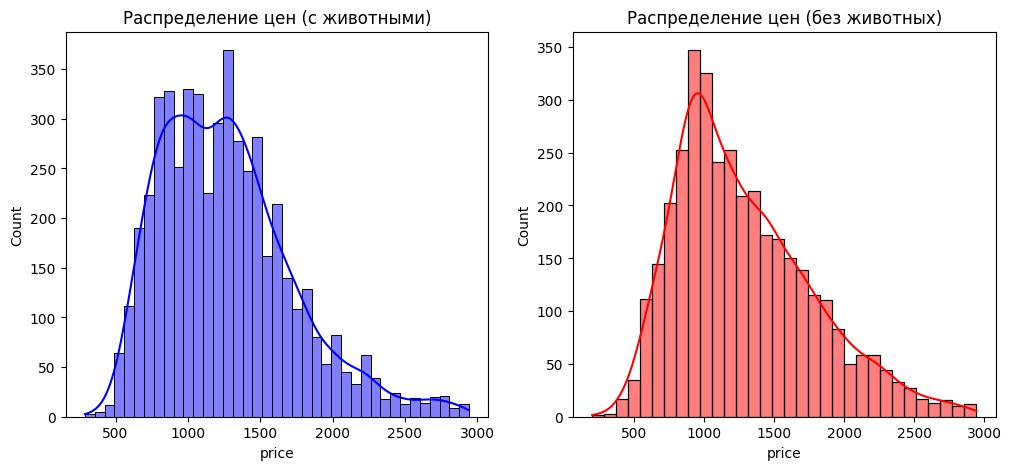

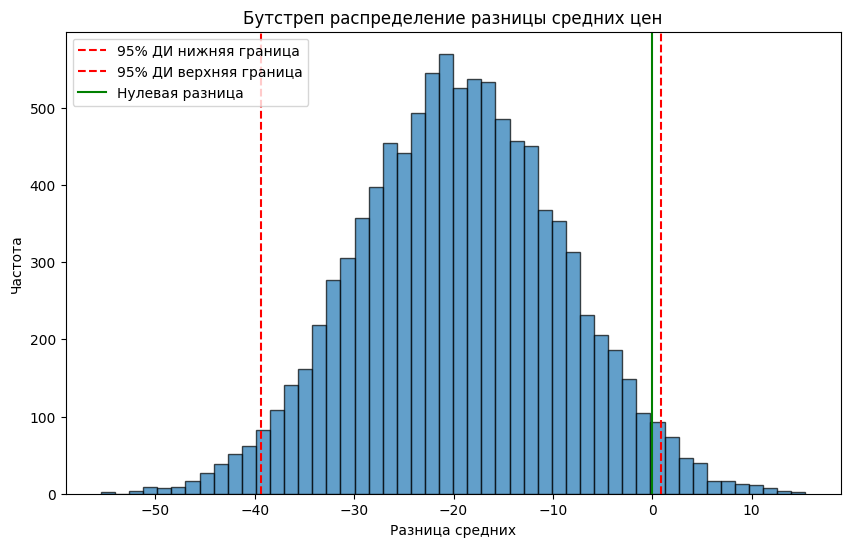

In [ ]:
# Визуализация распределений
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(group_1, kde=True, ax=axes[0], color='blue', label='С животными')
sns.histplot(group_2, kde=True, ax=axes[1], color='red', label='Без животных')

axes[0].set_title('Распределение цен (с животными)')
axes[1].set_title('Распределение цен (без животных)')
plt.show()

# Бутстреп гистограмма
plt.figure(figsize=(10, 6))
plt.hist(boot_diffs, bins=50, edgecolor='black', alpha=0.7)
plt.axvline(ci_lower, color='red', linestyle='--', label='95% ДИ нижняя граница')
plt.axvline(ci_upper, color='red', linestyle='--', label='95% ДИ верхняя граница')
plt.axvline(0, color='green', linestyle='-', label='Нулевая разница')
plt.xlabel('Разница средних')
plt.ylabel('Частота')
plt.title('Бутстреп распределение разницы средних цен')
plt.legend()
plt.show()

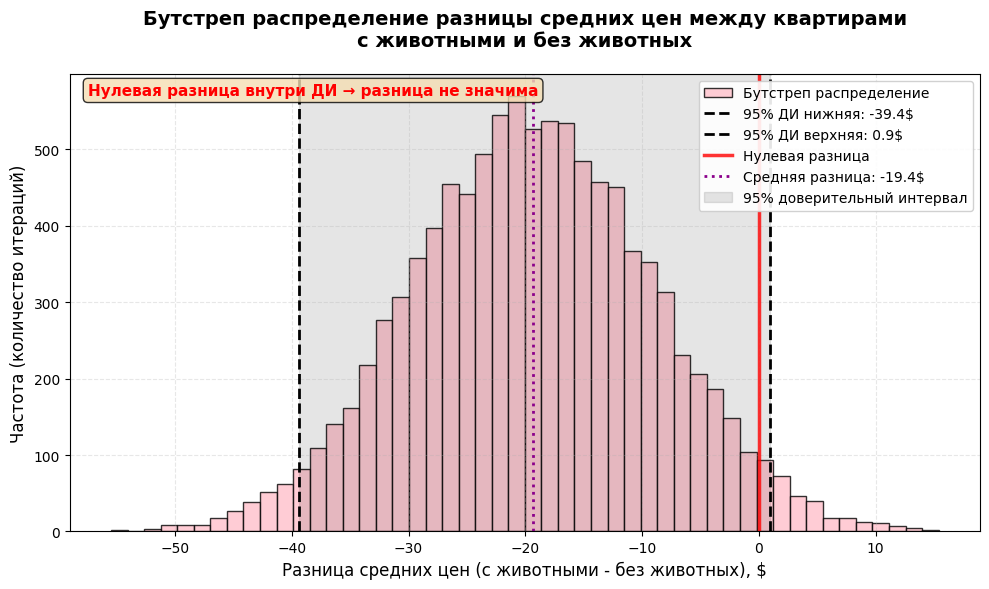

In [ ]:
# Бутстреп гистограмма
plt.figure(figsize=(10, 6))

# Гистограмма с розовым цветом
plt.hist(boot_diffs, bins=50, color='pink', edgecolor='black', alpha=0.8,
         label='Бутстреп распределение')

# Линии доверительного интервала и нулевой разницы
plt.axvline(ci_lower, color='black', linestyle='--', linewidth=2,
            label=f'95% ДИ нижняя: {ci_lower:.1f}$')
plt.axvline(ci_upper, color='black', linestyle='--', linewidth=2,
            label=f'95% ДИ верхняя: {ci_upper:.1f}$')
plt.axvline(0, color='red', linestyle='-', linewidth=2.5,
            label='Нулевая разница', alpha=0.8)

# Линия среднего значения
mean_line = plt.axvline(mean_diff, color='darkmagenta', linestyle=':', linewidth=2,
                       label=f'Средняя разница: {mean_diff:.1f}$')

# Заполнение доверительного интервала
plt.axvspan(ci_lower, ci_upper, color='black', alpha=0.1, label='95% доверительный интервал')

# Настройки графика
plt.xlabel('Разница средних цен (с животными - без животных), $', fontsize=12)
plt.ylabel('Частота (количество итераций)', fontsize=12)
plt.title('Бутстреп распределение разницы средних цен между квартирами\nс животными и без животных',
          fontsize=14, fontweight='bold', pad=20)
plt.grid(True, alpha=0.3, linestyle='--')
plt.legend(loc='upper right', fontsize=10, framealpha=0.9)

# Добавляем текстовую аннотацию
if ci_lower < 0 < ci_upper:
    conclusion = "Нулевая разница внутри ДИ → разница не значима"
    text_color = 'red'
else:
    conclusion = "Нулевая разница вне ДИ → разница значима"
    text_color = 'green'

plt.text(0.02, 0.98, conclusion,
         transform=plt.gca().transAxes,
         fontsize=11,
         color=text_color,
         fontweight='bold',
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.show()

Средняя разница отрицательная (-19.36) → квартиры с животными в среднем дешевле

Бутстрэп интервал включает 0 - метод также не показывает стат.значимости

##Выводы

###Гипотеза 1

Сравниваются 3 группы (1, 2, 3+ комнаты). Проверка на гомогенность дисперсий (тест Левена) показала p-value = 0.0000, значит дисперсии не равны.
Поэтому используется Welch ANOVA (устойчива к неравенству дисперсий).
Для попарного сравнения — Games-Howell, так как он не требует равенства дисперсий и численности групп.

Есть статистически значимая связь между количеством комнат и ценой за кв.ед. Однокомнатные квартиры оказываются дороже за единицу площади, что может быть связано с их большей рентабельностью и спросом на компактное жилье.


1.   Инсайт важен для арендодателей и инвесторов: при ограниченном бюджете выгоднее сдавать несколько однушек, чем одну большую квартиру
2.   Для владельцев жилья — сигнал, что компактное жильё может быть более рентабельным при сдаче
3.   Для платформ аренды — возможность рекомендовать пользователям более выгодные по площади варианты





###Гипотеза 2


Обе переменные — категориальные.
Используется хи-квадрат тест независимости.
Условие по ожидаемым частотам (все > 5) выполнено.

Есть статистически значимая связь между количеством комнат и количеством удобств. Однокомнатные квартиры чаще имеют 3+ удобства, что может отражать позиционирование таких квартир как компактных, но комфортных. В то время как двухкомнатные — более базовые, но просторные.




1.   Инсайт может быть учтен при разработке маркетинговых кампаний: однушки — как «всё включено», а двушки — как «простор без излишеств»
2.   Для владельцев недвижимости — ориентир, сколько удобств стоит добавить, чтобы повысить привлекательность жилья
3.   Для платформ подбора жилья — возможность улучшить фильтры и рекомендации, учитывая тип квартиры и набор удобств




###Гипотеза 3

Сравниваются две группы по среднему значению числовой переменной (цена).
Проверка гомогенности дисперсий (тест Левена) показала p < 0.001 → дисперсии не равны.
Применяется t-test Уэлча, устойчивый к неравенству дисперсий.
Дополнительно — бутстрэп для оценки доверительного интервала разницы средних.

Гипотеза не подтверждается. Разница в цене между квартирами, где разрешены животные, и где нет — статистически незначима. Это может быть связано с разными стратегиями ценообразования: в дешёвых квартирах разрешают животных из-за изношенности, а в дорогих — за счёт pet-friendly политики или доплаты.



1.   Инсайт может снизить опасения арендодателей, что pet-friendly политика обязательно приведёт к снижению дохода
2.   Для арендных платформ — возможность не учитывать этот фактор как ценообразующий, но использовать его для фильтрации по предпочтениям арендаторов
3.   Для арендаторов с животными — подтверждение, что наличие питомца не обязательно означает переплату

